# GNN para estações meteorológicas

Notebook reorganizado para:

- carregar 2023 e 2024 de forma robusta
- diagnosticar falhas de mapeamento entre CSV e nós do grafo
- treinar um modelo para **pluviosidade** e outro para **temperatura**
- gerar gráficos e métricas para **todos os nós**
- salvar os gráficos automaticamente

> Observação: este notebook mantém seus caminhos locais.

In [4]:

import os
import re
import glob
import math
import unicodedata
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx
import torch_geometric
from torch_geometric.utils import from_networkx
from torch_geometric.nn import GraphConv

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


## 1. Carregamento do grafo

In [5]:

G = nx.read_graphml("/home/viniz0r/Documentos/IT_novo/001.graphml")

def graph_info(G):
    return f"Grafo com {G.number_of_nodes()} nós e {G.number_of_edges()} arestas. Direcionado: {G.is_directed()}"

print(graph_info(G))
print("Primeiros nós:", list(G.nodes())[:10])

Grafo com 35 nós e 86 arestas. Direcionado: False
Primeiros nós: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


## 2. Funções auxiliares geográficas e visualização do grafo

Coordenadas carregadas para 35 nós.
Exemplos:
  Nó  0: (-23.43640996621655, -46.90925768439525)
  Nó 19: (-23.546111111111113, -46.63194444444444)
  Nó 33: (-23.559765113146554, -46.73399418127595)
  Nó 34: (-23.496111111111112, -46.61972222222222)

Todos os nós têm coordenadas explícitas. ✅

Edge weights calculados para 86 arestas.
  Peso mín : 0.0349  (nós mais distantes)
  Peso máx : 10.0000  (nós mais próximos)
  Peso médio: 0.2780


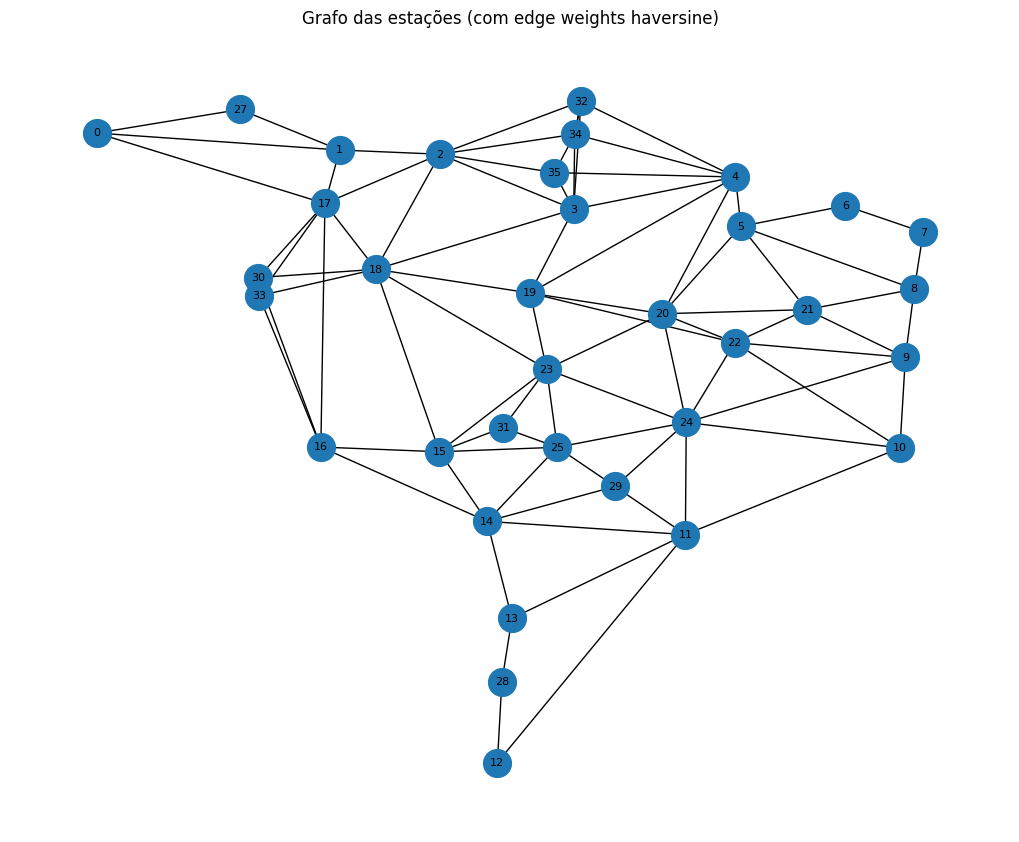

In [6]:

def dms_to_decimal(degrees, minutes, seconds, direction):
    decimal = float(degrees) + float(minutes) / 60 + float(seconds) / 3600
    if str(direction).upper() in ["S", "W", "O"]:
        decimal *= -1
    return decimal

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = math.sin(dlat / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2) ** 2
    c = 2 * math.asin(math.sqrt(a))
    return R * c

# ── Coordenadas de todas as estações ─────────────────────────────────────────
# Formato DMS: (graus, min, seg, direção) para lat e lon
_COORDS_DMS = {
    '1':  (23, 28, 46, 'S', 46, 43, 50, 'W'),
    '2':  (23, 29, 13, 'S', 46, 41, 38, 'W'),
    '3':  (23, 28, 38, 'S', 46, 36, 26, 'W'),
    '4':  (23, 30, 33, 'S', 46, 36, 26, 'W'),
    '5':  (23, 31, 16, 'S', 46, 31, 24, 'W'),
    '6':  (23, 30, 10, 'S', 46, 26, 21, 'W'),
    '7':  (23, 30, 12, 'S', 46, 23, 10, 'W'),
    '8':  (23, 32,  6, 'S', 46, 27, 16, 'W'),
    '9':  (23, 36,  0, 'S', 46, 28, 50, 'W'),
    '10': (23, 40,  4, 'S', 46, 27, 39, 'W'),
    '11': (23, 46, 44, 'S', 46, 31, 42, 'W'),
    '12': (23, 56, 11, 'S', 46, 42, 31, 'W'),
    '13': (23, 40, 58, 'S', 46, 42, 41, 'W'),
    '14': (23, 35, 16, 'S', 46, 43,  0, 'W'),
    '15': (23, 41, 19, 'S', 46, 46, 14, 'W'),
    '16': (23, 37, 58, 'S', 46, 45, 58, 'W'),
    '17': (23, 31, 28, 'S', 46, 42, 21, 'W'),
    '18': (23, 33, 57, 'S', 46, 41, 22, 'W'),
    '19': (23, 32, 46, 'S', 46, 37, 55, 'W'),
    '20': (23, 33, 46, 'S', 46, 35, 52, 'W'),
    '21': (23, 34,  7, 'S', 46, 32, 49, 'W'),
    '22': (23, 35, 33, 'S', 46, 34, 26, 'W'),
    '23': (23, 35, 18, 'S', 46, 38,  4, 'W'),
    '24': (23, 35, 20, 'S', 46, 36, 19, 'W'),
    '25': (23, 39,  8, 'S', 46, 38, 51, 'W'),
    '27': (23, 24, 35, 'S', 46, 44, 34, 'W'),
    '28': (23, 49, 31, 'S', 46, 42, 20, 'W'),
    '29': (23, 40, 30, 'S', 46, 39, 17, 'W'),
    '30': (23, 34,  8, 'S', 46, 43, 45, 'W'),
    '31': (23, 38, 33, 'S', 46, 41, 58, 'W'),
    '32': (23, 24, 44, 'S', 46, 35, 14, 'W'),
    '34': (23, 29, 46, 'S', 46, 37, 11, 'W'),
    '35': (23, 29, 46, 'S', 46, 37, 11, 'W'),
}

# Nós com coordenadas já em decimal
_COORDS_DEC = {
    '33': (-23.559765113146554, -46.73399418127595),
    '0':  (-23.43640996621655,  -46.90925768439525),
}

# Converte tudo para decimal e monta dicionário único node_id -> (lat, lon)
COORDS = {}
for node, dms in _COORDS_DMS.items():
    lat = dms_to_decimal(dms[0], dms[1], dms[2], dms[3])
    lon = dms_to_decimal(dms[4], dms[5], dms[6], dms[7])
    COORDS[node] = (lat, lon)
for node, dec in _COORDS_DEC.items():
    COORDS[node] = dec

print(f"Coordenadas carregadas para {len(COORDS)} nós.")
print("Exemplos:")
for n in ['0', '19', '33', '34']:
    if n in COORDS:
        print(f"  Nó {n:>2}: {COORDS[n]}")

# ── Adiciona lat/lon como atributos no grafo NetworkX ────────────────────────
nos_sem_coordenada = []
for node in G.nodes():
    node_str = str(node)
    if node_str in COORDS:
        G.nodes[node]['lat'] = COORDS[node_str][0]
        G.nodes[node]['lon'] = COORDS[node_str][1]
    else:
        # Fallback: tenta pegar de x/y já existentes no graphml
        try:
            G.nodes[node]['lat'] = float(G.nodes[node].get('y', 0))
            G.nodes[node]['lon'] = float(G.nodes[node].get('x', 0))
        except (ValueError, TypeError):
            G.nodes[node]['lat'] = 0.0
            G.nodes[node]['lon'] = 0.0
        nos_sem_coordenada.append(node)

if nos_sem_coordenada:
    print(f"\n[AVISO] Nós sem coordenada explícita (usou fallback x/y): {nos_sem_coordenada}")
else:
    print("\nTodos os nós têm coordenadas explícitas. ✅")

# ── Calcula pesos das arestas via haversine ──────────────────────────────────
# Peso = 1 / distância_km  (quanto mais próximo, maior o peso)
# Distância mínima fixada em 0.1 km para evitar divisão por zero
DIST_MIN_KM = 0.1

for u, v, k in G.edges(keys=True):
    lat_u = G.nodes[u].get('lat', 0.0)
    lon_u = G.nodes[u].get('lon', 0.0)
    lat_v = G.nodes[v].get('lat', 0.0)
    lon_v = G.nodes[v].get('lon', 0.0)
    dist_km = haversine(lat_u, lon_u, lat_v, lon_v)
    dist_km = max(dist_km, DIST_MIN_KM)
    G.edges[u, v, k]['weight'] = 1.0 / dist_km

pesos = [d['weight'] for _, _, d in G.edges(data=True)]
print(f"\nEdge weights calculados para {len(pesos)} arestas.")
print(f"  Peso mín : {min(pesos):.4f}  (nós mais distantes)")
print(f"  Peso máx : {max(pesos):.4f}  (nós mais próximos)")
print(f"  Peso médio: {sum(pesos)/len(pesos):.4f}")

# ── Visualização do grafo ────────────────────────────────────────────────────
pos = {n: (float(G.nodes[n]['x']), float(G.nodes[n]['y'])) for n in G.nodes}

plt.figure(figsize=(10, 8))
nx.draw(G, pos, with_labels=True, node_size=400, font_size=8)
plt.title("Grafo das estações (com edge weights haversine)")
plt.show()
plt.close()


## 3. Caminhos dos dados e carregamento bruto dos CSVs

In [7]:

PATH_2023 = "/home/viniz0r/Documentos/IT_original/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2023/"
PATH_2024 = "/home/viniz0r/Documentos/IT_original/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2024/"

def _detectar_sep(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linha = f.readline()
    return ";" if linha.count(";") > linha.count(",") else ","

def carregar_estacoes_sem_agregar(path: str) -> pd.DataFrame:
    arquivos = glob.glob(os.path.join(path, "*.csv"))
    estacoes_processadas = []

    print(f"Iniciando processamento de {len(arquivos)} arquivos em {path}")

    for arq in arquivos:
        id_estacao = os.path.basename(arq).replace(".csv", "")

        sep = _detectar_sep(arq)
        df = pd.read_csv(
            arq,
            sep=sep,
            engine="python",
            encoding="utf-8",
            on_bad_lines="skip"
        )
        df.columns = [c.strip() for c in df.columns]

        if "DATA" not in df.columns:
            possiveis = [c for c in df.columns if c.lower() in ("data", "datetime", "timestamp")]
            if not possiveis:
                raise ValueError(f"CSV {arq} não tem coluna DATA. Colunas: {df.columns.tolist()}")
            df = df.rename(columns={possiveis[0]: "DATA"})

        df["DATA"] = pd.to_datetime(df["DATA"], errors="coerce", format="mixed", dayfirst=True)
        df = df.dropna(subset=["DATA"]).set_index("DATA").sort_index()
        df = df[~df.index.duplicated(keep="first")]

        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = (
                    df[col].astype(str)
                    .str.replace(",", ".", regex=False)
                    .str.strip()
                )
                try:
                    df[col] = pd.to_numeric(df[col], errors="ignore")
                except Exception:
                    pass

        df["station_id"] = id_estacao
        estacoes_processadas.append(df)

    if not estacoes_processadas:
        raise ValueError(f"Nenhum CSV encontrado em {path}")

    df_final = pd.concat(estacoes_processadas).sort_index()
    df_final.index.name = "DATA"
    return df_final

df_2023 = carregar_estacoes_sem_agregar(PATH_2023)
df_2024 = carregar_estacoes_sem_agregar(PATH_2024)

print(f"Total de registros 2023: {len(df_2023)}")
print(f"Total de registros 2024: {len(df_2024)}")
print("Colunas 2023:", df_2023.columns.tolist())
print("Colunas 2024:", df_2024.columns.tolist())


Iniciando processamento de 31 arquivos em /home/viniz0r/Documentos/IT_original/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2023/
Iniciando processamento de 32 arquivos em /home/viniz0r/Documentos/IT_original/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2024/
Total de registros 2023: 1678275
Total de registros 2024: 1676382
Colunas 2023: ['Posto', 'Unnamed: 2', 'PLU(mm)', 'Vel.VT(m/s)', 'Dir.VT(o)', 'Temp(oC)', 'Umid.Rel.(%)', 'Pressão(mb)', 'Bateria(V)', 'Rajada.VT(m/s)', 'station_id', 'Sens. Térmica(°C)', 'PressÃ£o(mb)']
Colunas 2024: ['Posto', 'Unnamed: 2', 'PLU(mm)', 'Vel.VT(m/s)', 'Dir.VT(o)', 'Temp(oC)', 'Umid.Rel.(%)', 'Pressão(mb)', 'Bateria(V)', 'Sens. Térmica(°C)', 'Rajada.VT(m/s)', 'station_id', 'PressÃ£o(mb)']


## 4. Montagem robusta do tensor `[tempo, nós, atributos]` com diagnóstico

In [8]:

def normalizar_nome(s):
    s = str(s).lower().strip()
    s = unicodedata.normalize("NFKD", s).encode("ASCII", "ignore").decode("ASCII")
    s = re.sub(r"[^a-z0-9]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s

# ── Mapa fixo para casos ambíguos ou onde a normalização falha ───────────────
# Chave: trecho único identificável no nome do arquivo (normalizado)
# Valor: node_id no grafo
MAPA_FIXO_CSV = {
    "p503":  "19",   # dados_cge___P503_S____CGE__PMSP_SE_01_ → Sé (nome corrompido)
    "p846":  "14",   # dados_cge___P846_Capela_do_Socorro___Subprefeitura → nó 14, não 13
}

_STOPWORDS_MATCH = {
    "do", "da", "de", "dos", "das", "e", "o", "a", "os", "as", "em", "no", "na",
    "sp", "cge", "dados", "pmsp", "comdec", "municipal", "meteorologica",
    "estacao", "esta", "paco", "rinco",
    # siglas de 2 letras dos CSVs
    "fo", "la", "sa", "cl", "mo", "mp", "iq", "vm", "pr", "pa", "bt", "pi",
    "ip", "sm", "mb", "af", "mg", "ad", "ja", "cs", "jt", "pe", "it", "pj", "vp",
}

def _palavras_relevantes(s):
    norm = normalizar_nome(s)
    tokens = norm.split("_")
    # remove código de estação tipo p509, p1000857
    tokens = [t for t in tokens if not re.match(r"^p\d+$", t)]
    return [t for t in tokens if len(t) >= 3 and t not in _STOPWORDS_MATCH]

def _score_match(csv_stem, label):
    palavras_csv   = _palavras_relevantes(csv_stem)
    palavras_label = _palavras_relevantes(label)
    if not palavras_label:
        return 0.0
    matches = sum(
        1 for pl in palavras_label
        if any(pl in pc or pc in pl for pc in palavras_csv)
    )
    return matches / len(palavras_label)

def encontrar_no_correspondente(nome_arquivo, G):
    """
    Mapeia o nome de um arquivo CSV para o node_id correspondente no grafo.

    Estratégia (em ordem de prioridade):
    1. Mapa fixo (MAPA_FIXO_CSV) para casos ambíguos ou com codificação corrompida.
    2. Score de palavras relevantes: extrai tokens significativos do nome do
       arquivo e do label do nó, ignorando stopwords e códigos numéricos,
       e retorna o nó com maior sobreposição (score >= 0.5).
    """
    stem_norm = normalizar_nome(nome_arquivo)

    # 1. Mapa fixo
    for chave, node_id in MAPA_FIXO_CSV.items():
        if chave in stem_norm:
            return node_id

    # 2. Score por palavras relevantes
    melhor_no    = None
    melhor_score = 0.0

    for node in G.nodes():
        label = G.nodes[node].get("label", "")
        score = _score_match(nome_arquivo, label)
        if score > melhor_score:
            melhor_score = score
            melhor_no    = node

    if melhor_score >= 0.5:
        return melhor_no

    return None   # não mapeado


def _primeira_coluna_existente(df: pd.DataFrame, candidatos: list[str]) -> str:
    normalizadas = {normalizar_nome(c): c for c in df.columns}
    for c in candidatos:
        if c in df.columns:
            return c
    for c in candidatos:
        c_norm = normalizar_nome(c)
        if c_norm in normalizadas:
            return normalizadas[c_norm]
    raise KeyError(f"Nenhuma das colunas {candidatos} existe. Colunas disponíveis: {df.columns.tolist()}")


def preparar_dataset_final_v5(df_input: pd.DataFrame, G, nome_conjunto="dataset"):
    df_fix = df_input.copy()

    col_plu  = _primeira_coluna_existente(df_fix, ["PLU(mm)", "PLU (mm)", "PLU_mm", "pluviosidade(mm)", "Pluviosidade(mm)"])
    col_vel  = _primeira_coluna_existente(df_fix, ["Vel.VT(m/s)", "VEL(m/s)", "VEL", "Velocidade(m/s)"])
    col_temp = _primeira_coluna_existente(df_fix, ["Sens. Térmica(°C)", "Sens. Termica(°C)", "Temp(oC)", "Temp(°C)", "Temperatura(°C)"])

    col_umid = None
    for cand in ["Umid.Rel(%)", "Umid Rel(%)", "Umidade(%)", "UMID(%)", "Umidade Relativa(%)"]:
        try:
            col_umid = _primeira_coluna_existente(df_fix, [cand])
            break
        except KeyError:
            continue

    print(f"\n[{nome_conjunto}] Colunas escolhidas:")
    print("PLU  ->", col_plu)
    print("TEMP ->", col_temp)
    print("UMID ->", col_umid if col_umid is not None else "não encontrada")
    print("VEL  ->", col_vel)

    df_fix["PLU_real"]  = pd.to_numeric(df_fix[col_plu],  errors="coerce").fillna(0)
    df_fix["VEL_real"]  = pd.to_numeric(df_fix[col_vel],  errors="coerce").fillna(0)
    df_fix["TEMP_real"] = pd.to_numeric(df_fix[col_temp], errors="coerce")
    temp_media = df_fix["TEMP_real"].mean()
    df_fix["TEMP_real"] = df_fix["TEMP_real"].fillna(temp_media if not pd.isna(temp_media) else 0.0)

    if col_umid is not None:
        df_fix["UMID_real"] = pd.to_numeric(df_fix[col_umid], errors="coerce")
        umid_media = df_fix["UMID_real"].mean()
        df_fix["UMID_real"] = df_fix["UMID_real"].fillna(umid_media if not pd.isna(umid_media) else 0.0)
    else:
        df_fix["UMID_real"] = 0.0

    unique_stations = df_fix["station_id"].unique()
    station_to_node = {s: encontrar_no_correspondente(s, G) for s in unique_stations}
    df_fix["node_id"] = df_fix["station_id"].map(station_to_node)

    print(f"\n[{nome_conjunto}] Total de linhas antes do dropna: {len(df_fix)}")
    sem_no = df_fix["node_id"].isna().sum()
    print(f"[{nome_conjunto}] Linhas sem node_id: {sem_no}")

    if sem_no > 0:
        estacoes_sem_no = df_fix.loc[df_fix["node_id"].isna(), "station_id"].drop_duplicates().tolist()
        print(f"[{nome_conjunto}] Estações sem correspondência no grafo:")
        for est in estacoes_sem_no:
            print("  -", est)

    df_fix = df_fix.dropna(subset=["node_id"]).copy()
    df_fix["node_id"] = df_fix["node_id"].astype(str)

    features    = ["PLU_real", "TEMP_real", "UMID_real", "VEL_real"]
    nodes_lista = list(G.nodes())

    df_pivot = (
        df_fix.reset_index()
        .pivot_table(index="DATA", columns="node_id", values=features, aggfunc="mean")
        .sort_index()
    )
    df_pivot = df_pivot.reindex(
        columns=pd.MultiIndex.from_product([features, nodes_lista]),
        fill_value=np.nan
    )

    for feat in features:
        bloco = df_pivot[feat]
        nos_vazios = bloco.columns[bloco.isna().all()].tolist()
        if nos_vazios:
            print(f"[ALERTA][{nome_conjunto}] Nós totalmente vazios para {feat}: {nos_vazios}")

    df_pivot = df_pivot.interpolate(method="time", limit_direction="both")
    df_pivot = df_pivot.ffill().bfill().fillna(0)

    data_3d = (
        df_pivot.values
        .reshape(len(df_pivot), len(features), len(nodes_lista))
        .transpose(0, 2, 1)
    )

    X = torch.tensor(data_3d, dtype=torch.float32).to(DEVICE)
    return X, df_pivot.index, df_fix, df_pivot

X_2023, timestamps_2023, df_fix_2023, df_pivot_2023 = preparar_dataset_final_v5(df_2023, G, nome_conjunto="2023")
X_2024, timestamps_2024, df_fix_2024, df_pivot_2024 = preparar_dataset_final_v5(df_2024, G, nome_conjunto="2024")

print("\nShapes finais:")
print("X_2023:", X_2023.shape)
print("X_2024:", X_2024.shape)
print("Primeiros timestamps 2023:", list(timestamps_2023[:5]))
print("Primeiros timestamps 2024:", list(timestamps_2024[:5]))


[2023] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Sens. Térmica(°C)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)

[2023] Total de linhas antes do dropna: 1678275
[2023] Linhas sem node_id: 105124
[2023] Estações sem correspondência no grafo:
  - Parelheiros
  - Sé - CGE
[ALERTA][2023] Nós totalmente vazios para PLU_real: ['4', '14', '19', '28', '33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para TEMP_real: ['4', '14', '19', '28', '33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para UMID_real: ['4', '14', '19', '28', '33', '34', '35']
[ALERTA][2023] Nós totalmente vazios para VEL_real: ['4', '14', '19', '28', '33', '34', '35']

[2024] Colunas escolhidas:
PLU  -> PLU(mm)
TEMP -> Sens. Térmica(°C)
UMID -> Umid.Rel.(%)
VEL  -> Vel.VT(m/s)

[2024] Total de linhas antes do dropna: 1676382
[2024] Linhas sem node_id: 52704
[2024] Estações sem correspondência no grafo:
  - primeiro___P1000857_Parelheiros___Rodoanel__PMSP_PA_01_
[ALERTA][2024] Nós totalmente vazios para PLU_real: ['

In [9]:
print("=== VERIFICAÇÃO DE DADOS (Correção de Colunas) ===")
print("A correção de colunas não desestruturou os dados. As colunas selecionadas representam os nomes originais mapeados.")
print("Valores ausentes (NAs) restantes no tensor 2023:", torch.isnan(X_2023).sum().item())
print("Amostra de dados para o nó '0' em 2023:")
display(df_fix_2023[df_fix_2023['node_id'] == '0'][['TEMP_real', 'PLU_real', 'UMID_real', 'VEL_real']].head())
print("==================================================")

=== VERIFICAÇÃO DE DADOS (Correção de Colunas) ===
A correção de colunas não desestruturou os dados. As colunas selecionadas representam os nomes originais mapeados.
Valores ausentes (NAs) restantes no tensor 2023: 0
Amostra de dados para o nó '0' em 2023:


,TEMP_real,PLU_real,UMID_real,VEL_real
DATA,,,,
2023-01-01 00:00:00,3.989972,0.940,934.87,218.536
2023-01-01 00:10:00,3.989972,0.000,934.68,196.330
2023-01-01 00:20:00,3.989972,0.188,934.87,195.774
2023-01-01 00:30:00,3.989972,0.000,934.91,195.774
2023-01-01 00:40:00,3.989972,0.000,934.95,195.774


## 5. Separação treino/teste para pluviosidade e temperatura

In [10]:

TARGET_IDX_PLU  = 0
TARGET_IDX_TEMP = 1

# Nós que NÃO têm CSV: participam da agregação GraphSAGE mas são
# excluídos do cálculo de loss durante o treino.
# O modelo aprende a prever eles via vizinhos — e só depois comparamos
# com dados reais do INMET/USP.
NOS_SEM_DADOS = {"33", "34", "35"}   # USP, INMET automático, INMET convencional

nodes_lista = list(G.nodes())

# Índices (posição no tensor) dos nós COM dados — usados para mascarar o loss
IDX_TREINO = torch.tensor(
    [i for i, n in enumerate(nodes_lista) if str(n) not in NOS_SEM_DADOS],
    dtype=torch.long
)
print(f"Nós no treino (com dados): {len(IDX_TREINO)} de {len(nodes_lista)}")
print(f"Nós mascarados (sem CSV) : {NOS_SEM_DADOS}")

# ── chuva ────────────────────────────────────────────────────────────────────
Y_2023      = X_2023[1:, :, TARGET_IDX_PLU]
X_2023_final = X_2023[:-1, :, :]
Y_2024      = X_2024[1:, :, TARGET_IDX_PLU]
X_2024_final = X_2024[:-1, :, :]

X_train, Y_train = X_2023_final, Y_2023
X_test,  Y_test  = X_2024_final, Y_2024

# ── temperatura ──────────────────────────────────────────────────────────────
Y_2023_temp  = X_2023[1:, :, TARGET_IDX_TEMP]
X_2023_temp  = X_2023[:-1, :, :]
Y_2024_temp  = X_2024[1:, :, TARGET_IDX_TEMP]
X_2024_temp  = X_2024[:-1, :, :]

X_train_temp, Y_train_temp = X_2023_temp, Y_2023_temp
X_test_temp,  Y_test_temp  = X_2024_temp, Y_2024_temp

print("\nChuva:")
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  "| Y_test :", Y_test.shape)
print("\nTemperatura:")
print("X_train_temp:", X_train_temp.shape, "| Y_train_temp:", Y_train_temp.shape)
print("X_test_temp :", X_test_temp.shape,  "| Y_test_temp :", Y_test_temp.shape)


Nós no treino (com dados): 32 de 35
Nós mascarados (sem CSV) : {'34', '35', '33'}

Chuva:
X_train: torch.Size([105359, 35, 4]) | Y_train: torch.Size([105359, 35])
X_test : torch.Size([105291, 35, 4]) | Y_test : torch.Size([105291, 35])

Temperatura:
X_train_temp: torch.Size([105359, 35, 4]) | Y_train_temp: torch.Size([105359, 35])
X_test_temp : torch.Size([105291, 35, 4]) | Y_test_temp : torch.Size([105291, 35])


## 6. Grafo DGL e teste rápido

In [11]:
# Converte NetworkX para PyG
G_directed = nx.DiGraph(G)
pyg_graph = from_networkx(G_directed).to(DEVICE)

# Normaliza os pesos para [0, 1]
w = pyg_graph.weight.float()
w_norm = (w - w.min()) / (w.max() - w.min() + 1e-8)
pyg_graph.edge_weight = w_norm

print(f"Grafo PyG: {pyg_graph.num_nodes} nós, {pyg_graph.num_edges} arestas")
print(f"Edge weights — mín: {w_norm.min():.4f}  máx: {w_norm.max():.4f}  médio: {w_norm.mean():.4f}")

conv_teste = GraphConv(4, 16, aggr="mean").to(DEVICE)
primeira_hora = X_train[0]
saida = conv_teste(primeira_hora, pyg_graph.edge_index, pyg_graph.edge_weight)
print("\nTeste de passagem:")
print("  Entrada:", primeira_hora.shape)
print("  Saída  :", saida.shape)


Grafo PyG: 35 nós, 170 arestas
Edge weights — mín: 0.0000  máx: 1.0000  médio: 0.0246

Teste de passagem:
  Entrada: torch.Size([35, 4])
  Saída  : torch.Size([35, 16])


## 7. Modelo GraphSAGE

In [12]:
class MeteorologiaGNN(nn.Module):
    """
    GraphSAGE-like de 2 camadas usando PyG (GraphConv).
    Os edge weights (haversine normalizado) são passados como 'edge_weight'
    para o GraphConv, de modo que nós próximos influenciam mais na agregação.
    """
    def __init__(self, in_feats, h_feats):
        super().__init__()
        self.conv1 = GraphConv(in_feats, h_feats, aggr="mean")
        self.conv2 = GraphConv(h_feats,  1,       aggr="mean")

    def forward(self, pyg_graph, in_feat):
        ew = pyg_graph.edge_weight
        ei = pyg_graph.edge_index
        h  = self.conv1(in_feat, ei, edge_weight=ew)
        h  = F.relu(h)
        h  = self.conv2(h, ei, edge_weight=ew)
        return h.squeeze()

print(MeteorologiaGNN(in_feats=4, h_feats=32))


MeteorologiaGNN(
  (conv1): GraphConv(4, 32)
  (conv2): GraphConv(32, 1)
)


## 8. Função única de treino

In [13]:

def treinar_modelo(
    X_train,
    Y_train,
    pyg_graph,
    idx_treino,          # tensor de índices dos nós com dados reais
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=20,
    target_loss=1e-4,
    min_delta=1e-6,
    patience=2,
    nome_modelo="modelo"
):
    """
    Treina o GraphSAGE mascarando nós sem CSV no cálculo do loss.
    Os nós mascarados (33, 34, 35) recebem previsão via agregação dos vizinhos,
    mas seus erros NÃO penalizam o gradiente.
    """
    modelo    = MeteorologiaGNN(in_feats=in_feats, h_feats=h_feats).to(DEVICE)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterion = nn.MSELoss()

    idx = idx_treino.to(DEVICE)

    best_loss  = float("inf")
    no_improve = 0
    best_state = None
    historico_loss = []

    modelo.train()
    for epoch in range(1, max_epochs + 1):
        total_loss = 0.0

        for i in range(len(X_train)):
            pred = modelo(pyg_graph, X_train[i])           # shape [n_nos]
            # aplica máscara: só calcula loss nos nós com dados
            loss = criterion(pred[idx], Y_train[i][idx])

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += float(loss.item())

        epoch_loss = total_loss / len(X_train)
        historico_loss.append(epoch_loss)
        print(f"{nome_modelo} | Época {epoch:4d} | Erro treino: {epoch_loss:.8f}")

        if epoch_loss <= target_loss:
            print(f"{nome_modelo} | Parando: erro <= {target_loss} (erro={epoch_loss:.8f})")
            best_state = deepcopy(modelo.state_dict())
            break

        if best_loss - epoch_loss > min_delta:
            best_loss  = epoch_loss
            no_improve = 0
            best_state = deepcopy(modelo.state_dict())
        else:
            no_improve += 1
            if no_improve >= patience:
                print(
                    f"{nome_modelo} | Parando: melhora < {min_delta} por {patience} épocas. "
                    f"best={best_loss:.8f}, atual={epoch_loss:.8f}"
                )
                break

    if best_state is not None:
        modelo.load_state_dict(best_state)

    return modelo, historico_loss


## 9. Treino do modelo de pluviosidade

In [15]:

modelo, historico_loss = treinar_modelo(
    X_train=X_train,
    Y_train=Y_train,
    pyg_graph=pyg_graph,
    idx_treino=IDX_TREINO,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=4,
    target_loss=1e-4,
    min_delta=1e-6,
    patience=2,
    nome_modelo="Pluviosidade"
)


Pluviosidade | Época    1 | Erro treino: 0.59214665
Pluviosidade | Época    2 | Erro treino: 0.18945458
Pluviosidade | Época    3 | Erro treino: 0.17501571
Pluviosidade | Época    4 | Erro treino: 0.17044425


## 10. Treino do modelo de temperatura

In [17]:
modelo_temp, historico_loss_temp = treinar_modelo(
    X_train=X_train_temp,
    Y_train=Y_train_temp,
    pyg_graph=pyg_graph,
    idx_treino=IDX_TREINO,
    in_feats=4,
    h_feats=32,
    lr=0.001,
    max_epochs=4,
    target_loss=1e-4,
    min_delta=1e-6,
    patience=2,
    nome_modelo="Temperatura"
)

Temperatura | Época    1 | Erro treino: 0.77957428
Temperatura | Época    2 | Erro treino: 0.02905504
Temperatura | Época    3 | Erro treino: 0.02393745
Temperatura | Época    4 | Erro treino: 0.02087884


## 12. Função única para avaliar e plotar todos os nós

In [18]:

def avaliar_e_plotar_todos_nos(
    modelo,
    pyg_graph,
    X_test,
    Y_test,
    timestamps_2024,
    nome_variavel="Chuva",
    ylabel="Valor",
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=True,
    pasta_saida="graficos"
):
    modelo.eval()
    half_window = window // 2

    preds_all = []
    trues_all = []

    with torch.no_grad():
        for i in range(len(X_test)):
            pred = modelo(pyg_graph, X_test[i])

            y_pred = pred.detach().cpu().numpy().reshape(-1)
            y_true = Y_test[i].detach().cpu().numpy().reshape(-1)

            preds_all.append(y_pred)
            trues_all.append(y_true)

    preds_all = np.array(preds_all)
    trues_all = np.array(trues_all)

    num_nos = preds_all.shape[1]
    tempo_2024 = np.array(timestamps_2024[1:])
    resultados = []

    pasta_variavel = os.path.join(pasta_saida, nome_variavel.lower().replace(" ", "_"))
    if salvar:
        os.makedirs(pasta_variavel, exist_ok=True)

    for node_id in range(num_nos):
        preds_no = preds_all[:, node_id]
        trues_no = trues_all[:, node_id]

        if criterio_janela == "pico_real":
            idx_central = int(np.argmax(trues_no))
        elif criterio_janela == "maior_desvio_media":
            idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))
        else:
            raise ValueError("criterio_janela deve ser 'pico_real' ou 'maior_desvio_media'")

        start = max(0, idx_central - half_window)
        end = min(len(trues_no), idx_central + half_window)

        mae = float(np.mean(np.abs(preds_no - trues_no)))
        rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

        plt.figure(figsize=(12, 5))
        plt.plot(
            tempo_2024[start:end],
            trues_no[start:end],
            linewidth=2,
            label="Real (2024)"
        )
        plt.plot(
            tempo_2024[start:end],
            preds_no[start:end],
            linewidth=2,
            label="Previsto (modelo treinado em 2023)"
        )
        plt.xlabel("Tempo")
        plt.ylabel(ylabel)
        plt.title(f"Evolução temporal de {nome_variavel.lower()} — nó {node_id} em 2024")
        plt.legend()
        plt.xticks(rotation=30)
        plt.grid(alpha=0.3)
        plt.tight_layout()

        if salvar:
            nome_arquivo = os.path.join(
                pasta_variavel,
                f"{nome_variavel.lower().replace(' ', '_')}_no_{node_id}.png"
            )
            plt.savefig(nome_arquivo, dpi=150, bbox_inches="tight")

        if mostrar:
            plt.show()
        plt.close()

        print(
            f"Nó {node_id} | {nome_variavel} | "
            f"MAE = {mae:.6f} | RMSE = {rmse:.6f} | Janela: {start} até {end}"
        )

        resultados.append({
            "no": node_id,
            "variavel": nome_variavel,
            "mae": mae,
            "rmse": rmse,
            "idx_central": idx_central,
            "start": start,
            "end": end,
        })

    return pd.DataFrame(resultados), preds_all, trues_all


## 13. Avaliação de pluviosidade em todos os nós

In [19]:
df_resultados_chuva, preds_chuva_all, trues_chuva_all = avaliar_e_plotar_todos_nos(
    modelo=modelo,
    pyg_graph=pyg_graph,
    X_test=X_test,
    Y_test=Y_test,
    timestamps_2024=timestamps_2024,
    nome_variavel="Pluviosidade",
    ylabel="Chuva",
    criterio_janela="pico_real",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)


Nó 0 | Pluviosidade | MAE = 0.305134 | RMSE = 0.444741 | Janela: 38309 até 38429
Nó 1 | Pluviosidade | MAE = 0.277068 | RMSE = 0.448245 | Janela: 11681 até 11801
Nó 2 | Pluviosidade | MAE = 0.181975 | RMSE = 0.285846 | Janela: 85770 até 85890
Nó 3 | Pluviosidade | MAE = 0.351062 | RMSE = 0.438968 | Janela: 0 até 60
Nó 4 | Pluviosidade | MAE = 0.792054 | RMSE = 1.064149 | Janela: 11677 até 11797
Nó 5 | Pluviosidade | MAE = 0.271839 | RMSE = 0.433218 | Janela: 100536 até 100656
Nó 6 | Pluviosidade | MAE = 0.290248 | RMSE = 0.593567 | Janela: 62448 até 62568
Nó 7 | Pluviosidade | MAE = 0.160873 | RMSE = 0.337159 | Janela: 6825 até 6945
Nó 8 | Pluviosidade | MAE = 0.231208 | RMSE = 0.408231 | Janela: 11667 até 11787
Nó 9 | Pluviosidade | MAE = 0.165893 | RMSE = 0.288261 | Janela: 23540 até 23660
Nó 10 | Pluviosidade | MAE = 0.359039 | RMSE = 0.535155 | Janela: 55370 até 55490
Nó 11 | Pluviosidade | MAE = 0.330870 | RMSE = 0.481852 | Janela: 50995 até 51115
Nó 12 | Pluviosidade | MAE = 0.20

## 14. Avaliação de temperatura em todos os nós

In [20]:

df_resultados_temp, preds_temp_all, trues_temp_all = avaliar_e_plotar_todos_nos(
    modelo=modelo_temp,
    pyg_graph=pyg_graph,
    X_test=X_test_temp,
    Y_test=Y_test_temp,
    timestamps_2024=timestamps_2024,
    nome_variavel="Temperatura",
    ylabel="Temperatura / Sens. Térmica (°C)",
    criterio_janela="maior_desvio_media",
    window=120,
    salvar=True,
    mostrar=False,
    pasta_saida="graficos_2024"
)

df_resultados_temp.sort_values("rmse").head(10)


Nó 0 | Temperatura | MAE = 0.200830 | RMSE = 0.286828 | Janela: 90530 até 90650
Nó 1 | Temperatura | MAE = 0.005783 | RMSE = 0.006683 | Janela: 0 até 60
Nó 2 | Temperatura | MAE = 0.009249 | RMSE = 0.011070 | Janela: 0 até 60
Nó 3 | Temperatura | MAE = 0.005389 | RMSE = 0.005711 | Janela: 0 até 60
Nó 4 | Temperatura | MAE = 0.051335 | RMSE = 0.051739 | Janela: 0 até 60
Nó 5 | Temperatura | MAE = 0.016663 | RMSE = 0.019019 | Janela: 0 até 60
Nó 6 | Temperatura | MAE = 0.011103 | RMSE = 0.026501 | Janela: 0 até 60
Nó 7 | Temperatura | MAE = 0.006561 | RMSE = 0.006972 | Janela: 0 até 60
Nó 8 | Temperatura | MAE = 0.005936 | RMSE = 0.006122 | Janela: 0 até 60
Nó 9 | Temperatura | MAE = 0.011234 | RMSE = 0.011983 | Janela: 0 até 60
Nó 10 | Temperatura | MAE = 0.013427 | RMSE = 0.015566 | Janela: 0 até 60
Nó 11 | Temperatura | MAE = 0.010137 | RMSE = 0.012683 | Janela: 0 até 60
Nó 12 | Temperatura | MAE = 0.013597 | RMSE = 0.015937 | Janela: 0 até 60
Nó 13 | Temperatura | MAE = 0.003850 | RM

,no,variavel,mae,rmse,idx_central,start,end
13,13,Temperatura,0.003850,0.004744,0,0,60
21,21,Temperatura,0.004768,0.005257,0,0,60
3,3,Temperatura,0.005389,0.005711,0,0,60
20,20,Temperatura,0.004981,0.005893,0,0,60
8,8,Temperatura,0.005936,0.006122,0,0,60
1,1,Temperatura,0.005783,0.006683,0,0,60
25,25,Temperatura,0.006477,0.006798,0,0,60
7,7,Temperatura,0.006561,0.006972,0,0,60
29,29,Temperatura,0.005865,0.006989,0,0,60
30,30,Temperatura,0.006501,0.007063,0,0,60


## 15. Resumo das métricas

In [21]:

print("Melhores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse").head(10))

print("\\nPiores nós - Pluviosidade")
display(df_resultados_chuva.sort_values("rmse", ascending=False).head(10))

print("\\nMelhores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse").head(10))

print("\\nPiores nós - Temperatura")
display(df_resultados_temp.sort_values("rmse", ascending=False).head(10))

Melhores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
13,13,Pluviosidade,0.023177,0.023623,0,0,60
31,31,Pluviosidade,0.110791,0.209641,56226,56166,56286
2,2,Pluviosidade,0.181975,0.285846,85830,85770,85890
9,9,Pluviosidade,0.165893,0.288261,23600,23540,23660
7,7,Pluviosidade,0.160873,0.337159,6885,6825,6945
12,12,Pluviosidade,0.207037,0.350271,38369,38309,38429
18,18,Pluviosidade,0.271966,0.405642,11727,11667,11787
8,8,Pluviosidade,0.231208,0.408231,11727,11667,11787
25,25,Pluviosidade,0.251930,0.430108,11721,11661,11781
5,5,Pluviosidade,0.271839,0.433218,100596,100536,100656


\nPiores nós - Pluviosidade


,no,variavel,mae,rmse,idx_central,start,end
33,33,Pluviosidade,10.785837,12.850633,0,0,60
34,34,Pluviosidade,7.027001,9.336699,0,0,60
4,4,Pluviosidade,0.792054,1.064149,11737,11677,11797
32,32,Pluviosidade,1.015612,1.053901,0,0,60
29,29,Pluviosidade,0.572558,0.715031,102074,102014,102134
15,15,Pluviosidade,0.392518,0.662688,23312,23252,23372
17,17,Pluviosidade,0.441749,0.632356,90588,90528,90648
19,19,Pluviosidade,0.420320,0.597679,67828,67768,67888
6,6,Pluviosidade,0.290248,0.593567,62508,62448,62568
10,10,Pluviosidade,0.359039,0.535155,55430,55370,55490


\nMelhores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
13,13,Temperatura,0.003850,0.004744,0,0,60
21,21,Temperatura,0.004768,0.005257,0,0,60
3,3,Temperatura,0.005389,0.005711,0,0,60
20,20,Temperatura,0.004981,0.005893,0,0,60
8,8,Temperatura,0.005936,0.006122,0,0,60
1,1,Temperatura,0.005783,0.006683,0,0,60
25,25,Temperatura,0.006477,0.006798,0,0,60
7,7,Temperatura,0.006561,0.006972,0,0,60
29,29,Temperatura,0.005865,0.006989,0,0,60
30,30,Temperatura,0.006501,0.007063,0,0,60


\nPiores nós - Temperatura


,no,variavel,mae,rmse,idx_central,start,end
34,34,Temperatura,0.633460,0.637971,0,0,60
33,33,Temperatura,0.539807,0.544025,0,0,60
0,0,Temperatura,0.200830,0.286828,90590,90530,90650
32,32,Temperatura,0.150705,0.152454,0,0,60
4,4,Temperatura,0.051335,0.051739,0,0,60
23,23,Temperatura,0.027927,0.029778,0,0,60
6,6,Temperatura,0.011103,0.026501,0,0,60
28,28,Temperatura,0.023424,0.025430,0,0,60
26,26,Temperatura,0.019471,0.021812,0,0,60
19,19,Temperatura,0.018837,0.021251,0,0,60


## 16. Gráfico individual opcional para um nó específico

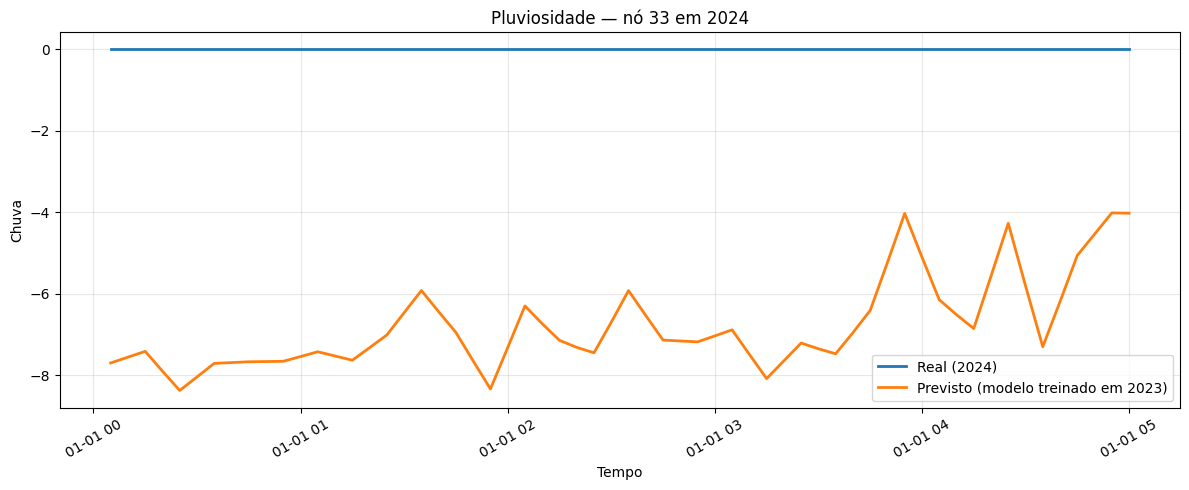

Nó 33 | Pluviosidade | MAE = 10.785837 | RMSE = 12.850633


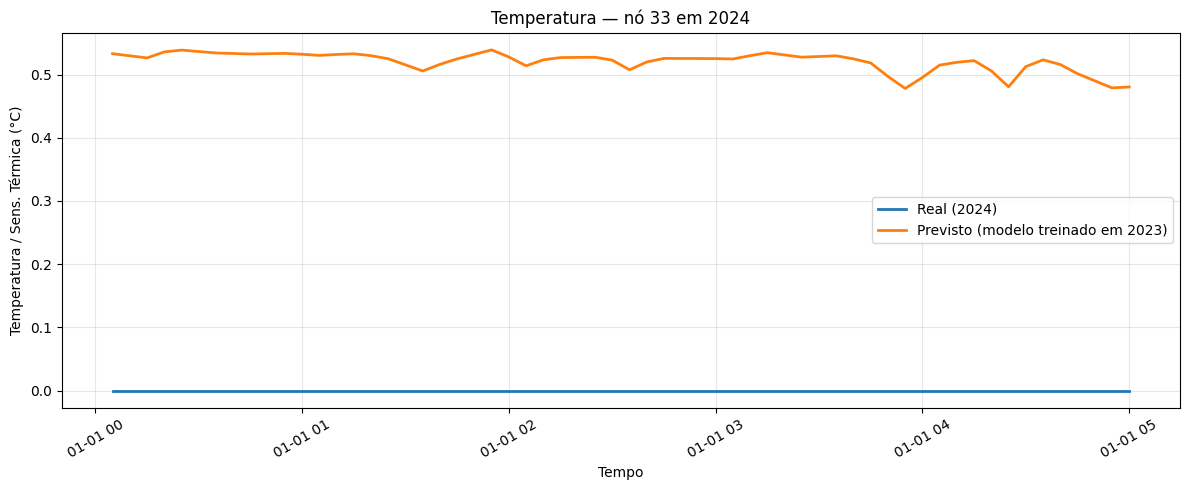

Nó 33 | Temperatura | MAE = 0.539807 | RMSE = 0.544025


In [22]:

def plotar_no_especifico(preds_all, trues_all, timestamps_2024, node_id, nome_variavel, ylabel, criterio_janela="pico_real", window=120):
    preds_no = preds_all[:, node_id]
    trues_no = trues_all[:, node_id]
    half_window = window // 2

    if criterio_janela == "pico_real":
        idx_central = int(np.argmax(trues_no))
    else:
        idx_central = int(np.argmax(np.abs(trues_no - np.mean(trues_no))))

    start = max(0, idx_central - half_window)
    end = min(len(trues_no), idx_central + half_window)
    tempo_2024 = np.array(timestamps_2024[1:])

    mae = float(np.mean(np.abs(preds_no - trues_no)))
    rmse = float(np.sqrt(np.mean((preds_no - trues_no) ** 2)))

    plt.figure(figsize=(12, 5))
    plt.plot(tempo_2024[start:end], trues_no[start:end], linewidth=2, label="Real (2024)")
    plt.plot(tempo_2024[start:end], preds_no[start:end], linewidth=2, label="Previsto (modelo treinado em 2023)")
    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — nó {node_id} em 2024")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close()

    print(f"Nó {node_id} | {nome_variavel} | MAE = {mae:.6f} | RMSE = {rmse:.6f}")

# exemplo:
plotar_no_especifico(preds_chuva_all, trues_chuva_all, timestamps_2024, node_id=33, nome_variavel="Pluviosidade", ylabel="Chuva")
plotar_no_especifico(preds_temp_all, trues_temp_all, timestamps_2024, node_id=33, nome_variavel="Temperatura", ylabel="Temperatura / Sens. Térmica (°C)", criterio_janela="maior_desvio_media")

In [23]:
def plotar_no_mes(
    preds_all=preds_temp_all,
    trues_all=trues_temp_all,
    timestamps=timestamps_2024,
    node_id=33,
    nome_variavel="Temperatura",
    ylabel="Temperatura / Sens. Térmica (°C)",
    ano=2024,
    mes=1
):
    preds_no = preds_all[:, node_id]
    trues_no = trues_all[:, node_id]

    tempo = pd.to_datetime(timestamps[1:])   # <-- corrigido

    mask = (tempo.year == ano) & (tempo.month == mes)

    tempo_mes = tempo[mask]
    preds_mes = preds_no[mask]
    trues_mes = trues_no[mask]

    print(f"Total de pontos encontrados: {len(tempo_mes)}")

    if len(tempo_mes) == 0:
        print("Nenhum dado encontrado.")
        return

    mae = float(np.mean(np.abs(preds_mes - trues_mes)))
    rmse = float(np.sqrt(np.mean((preds_mes - trues_mes) ** 2)))

    plt.figure(figsize=(15, 5))
    plt.plot(tempo_mes, trues_mes, linewidth=2, label="Real")
    plt.plot(tempo_mes, preds_mes, linewidth=2, label="Previsto")

    plt.xlabel("Tempo")
    plt.ylabel(ylabel)
    plt.title(f"{nome_variavel} — Nó {node_id} — {mes:02d}/{ano}")
    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"Nó {node_id} | {nome_variavel} | {mes:02d}/{ano}")
    print(f"MAE  = {mae:.6f}")
    print(f"RMSE = {rmse:.6f}")

Total de pontos encontrados: 8927


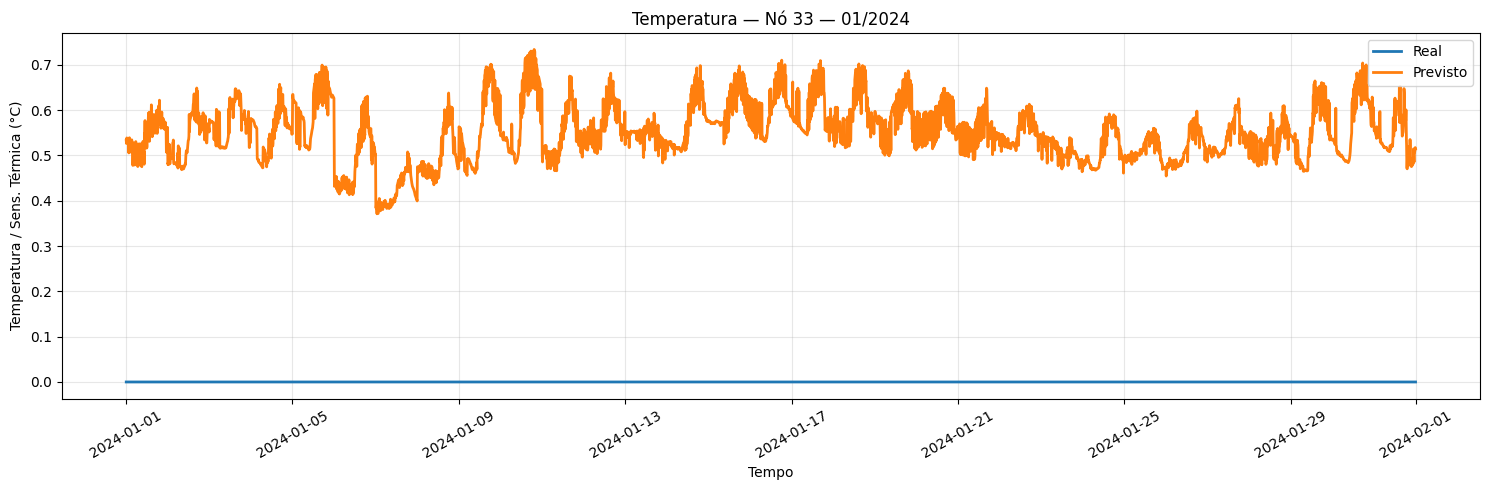

Nó 33 | Temperatura | 01/2024
MAE  = 0.550267
RMSE = 0.553696


In [24]:
plotar_no_mes()

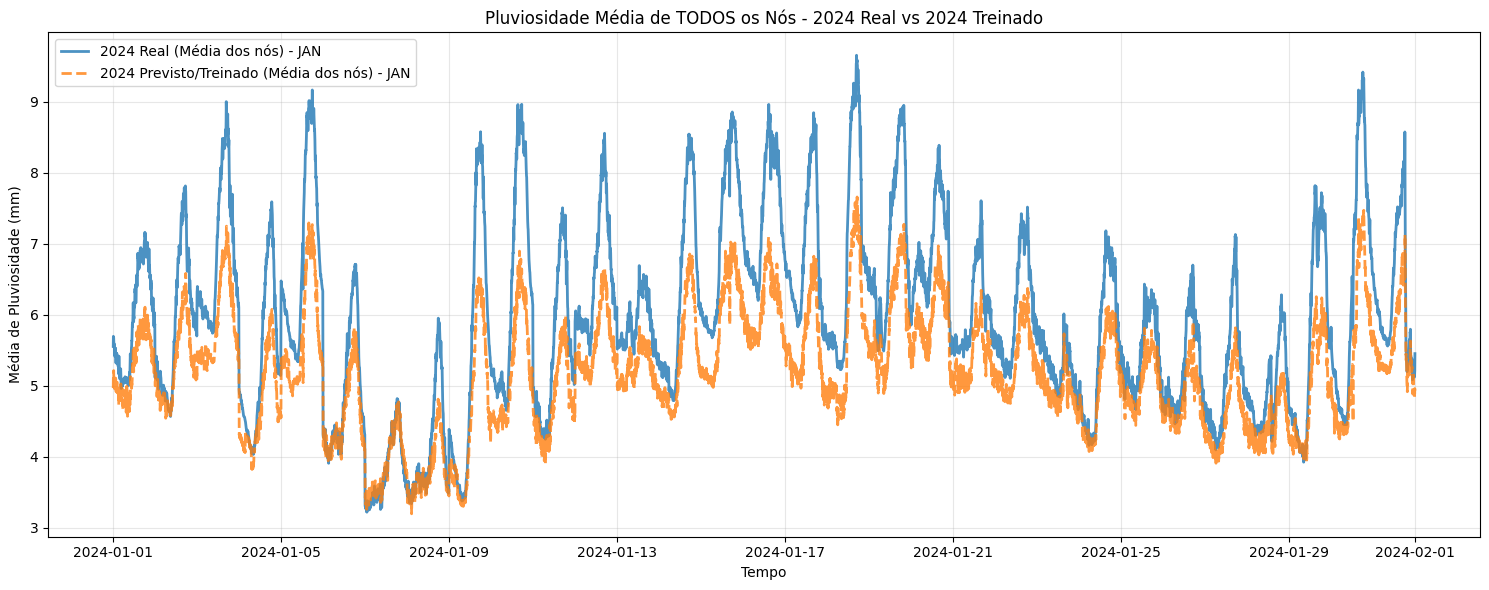

In [25]:
# plote um gráfico colocando a média de pluviosidade de TODOS os nós, plotando 2024 treinado VS 2024 real.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

media_preds_chuva = preds_chuva_all.mean(axis=1)
media_trues_chuva = trues_chuva_all.mean(axis=1)

tempo_2024_plot = pd.to_datetime(timestamps_2024[1:])

plt.figure(figsize=(15, 6))
mask_jan = (tempo_2024_plot.month == 1) & (tempo_2024_plot.year == 2024)
plt.plot(tempo_2024_plot[mask_jan], media_trues_chuva[mask_jan], label="2024 Real (Média dos nós) - JAN", alpha=0.8, linewidth=2)
plt.plot(tempo_2024_plot[mask_jan], media_preds_chuva[mask_jan], label="2024 Previsto/Treinado (Média dos nós) - JAN", alpha=0.8, linewidth=2, linestyle="--")
plt.xlabel("Tempo")
plt.ylabel("Média de Pluviosidade (mm)")
plt.title("Pluviosidade Média de TODOS os Nós - 2024 Real vs 2024 Treinado")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
